In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

# Clustering
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

# NLP
from sklearn.feature_extraction.text import TfidfVectorizer
import re
import unicodedata

# ── Semilla y fechas ─────────────────────────────────────────────────────────
SEED        = 42
FECHA_CORTE = pd.Timestamp("2025-12-31")
np.random.seed(SEED)

DATA_DIR    = Path("../data")
OUTPUT_DIR  = Path("../outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="Set2", font_scale=1.1)
print("✓ Librerías y configuración cargadas")


✓ Librerías y configuración cargadas


## 1. Carga de datos

In [2]:
# Clientes (demografía)
clientes = pd.read_csv(DATA_DIR / "clientes.csv", dtype={
    "id_cliente": str, "tipo_documento": str, "numero_documento": str,
    "nombre": str, "sexo": str, "estado_civil": str,
    "departamento": str, "municipio": str, "ocupacion": str,
    "tratamiento_datos": str,
})
clientes["fecha_nacimiento"] = pd.to_datetime(clientes["fecha_nacimiento"], errors="coerce")
clientes["fecha_creacion"]   = pd.to_datetime(clientes["fecha_creacion"],   errors="coerce")
clientes["numero_documento"] = clientes["numero_documento"].str.strip()

# Tabla de correspondencia id_cliente → id_canonico
corr = pd.read_csv(OUTPUT_DIR / "tabla_correspondencia.csv",
                   dtype={"id_cliente": str, "id_canonico": str})

# Valor CLV (sección 1)
clv = pd.read_csv(OUTPUT_DIR / "valor_cliente.csv",
                  dtype={"id_canonico": str})

# Riesgo de fuga (sección 2)
fuga = pd.read_csv(OUTPUT_DIR / "riesgo_fuga.csv",
                   dtype={"id_canonico": str})

# Roles de póliza → identificar TOMADORES (policyholders)
# Solo los tomadores pagan el servicio y son destinatarios reales de las campañas de mercadeo.
# Los asegurados pueden ser terceros (familiares, empleados) no vinculados comercialmente.
roles = pd.read_csv(DATA_DIR / "roles_poliza.csv",
                    dtype={"id_cliente": str, "codigo_poliza": str})
tomadores_ids = set(roles[roles["rol"] == "Tomador"]["id_cliente"].unique())
print(f"Roles cargados: {len(roles):,} filas | Roles únicos: {roles['rol'].unique()}")
print(f"Tomadores únicos (id_cliente): {len(tomadores_ids):,}")

# Encuestas de experiencia (sección 4)
exp = pd.read_csv(DATA_DIR / "experiencia.csv", dtype={
    "tipo_documento": str, "numero_documento": str
})
exp["numero_documento"] = exp["numero_documento"].astype(str).str.strip().str.split(".").str[0]
exp["comentario"] = exp["comentario"].fillna("").astype(str)

print(f"\nClientes: {len(clientes):,} filas")
print(f"Correspondencia: {len(corr):,} | CLV: {len(clv):,} | Fuga: {len(fuga):,} | Exp: {len(exp):,}")


Roles cargados: 275,398 filas | Roles únicos: <StringArray>
['Asegurado', 'Tomador']
Length: 2, dtype: str
Tomadores únicos (id_cliente): 64,665

Clientes: 102,764 filas
Correspondencia: 102,764 | CLV: 35,130 | Fuga: 35,130 | Exp: 99,775


## 2. Construcción de variables demográficas

### 2.1 Variables disponibles y decisión de inclusión / exclusión

| Variable | Incluida | Razón |
|---|---|---|
| `fecha_nacimiento` → edad | ✅ Sí | Determinante del ciclo de vida, necesidades aseguradoras y tolerancia al riesgo |
| `estrato` (1-6) | ✅ Sí | Proxy directa de nivel socioeconómico validado en Colombia |
| `ingreso_estimado` | ✅ Sí | Capacidad de pago; se imputa la media por estrato cuando falta |
| `ocupacion` | ✅ Sí | Define perfil de riesgo y tipo de cobertura requerida |
| `sexo` | ✅ Sí | Diferencia patrones de mortalidad, accidentalidad y uso de salud |
| `estado_civil` | ✅ Sí | Refleja carga familiar y necesidades de protección del hogar |
| `num_dependientes_menores` + mayores | ✅ Sí | Mide responsabilidades familiares; determina suma asegurada óptima |
| `departamento` → región | ✅ Sí | Disparidades en oferta de canales, riesgos regionales y acceso |
| `tipo_documento` → es_empresa | ✅ Sí | Empresas y personas naturales tienen necesidades estructuralmente distintas |
| `fecha_nacimiento` absoluta / `nombre` / `numero_documento` | ❌ No | Identificadores, no variables de perfil |
| Variables financiero-conductuales (prima, pagos, siniestros) | ❌ No | Corresponden a comportamiento, no a perfil demográfico; se usan solo en la caracterización |
| `municipio` (granular) | ❌ No | Demasiados niveles → ruido; se agrega a región |


In [3]:
# ── 2.1 Edad ─────────────────────────────────────────────────────────────────
clientes["edad"] = ((FECHA_CORTE - clientes["fecha_nacimiento"]).dt.days / 365.25).round(1)

# ── 2.2 Tipo de cliente ───────────────────────────────────────────────────────
clientes["es_empresa"] = (clientes["tipo_documento"] == "NIT").astype(int)

# ── 2.3 Ocupación agrupada ────────────────────────────────────────────────────
ocup_map = {
    "Empleado":        "Empleado",
    "Independiente":   "Independiente",
    "Pensionado":      "Pensionado/Rentista",
    "Rentista":        "Pensionado/Rentista",
    "Empresario":      "Empresario",
    "Desempleado":     "Sin ingreso fijo",
    "Menor de edad":   "Sin ingreso fijo",
    "Ama de casa":     "Sin ingreso fijo",
    "Estudiante":      "Sin ingreso fijo",
}
clientes["ocupacion_cat"] = clientes["ocupacion"].map(ocup_map).fillna("Otro")

# ── 2.4 Estado civil binario (simplificado) ───────────────────────────────────
clientes["con_pareja"] = clientes["estado_civil"].isin(
    ["Casado", "Unión libre", "Union libre"]).astype(int)

# ── 2.5 Dependientes totales ──────────────────────────────────────────────────
clientes["num_dependientes"] = (
    clientes["num_dependientes_menores"].fillna(0) +
    clientes["num_dependientes_mayores"].fillna(0)
).astype(int)

# ── 2.6 Región ────────────────────────────────────────────────────────────────
region_map = {
    "Antioquia": "Eje Cafetero / Occidente",
    "Caldas":    "Eje Cafetero / Occidente",
    "Risaralda": "Eje Cafetero / Occidente",
    "Quindío":   "Eje Cafetero / Occidente",
    "Valle del Cauca": "Pacifico / Sur",
    "Nariño":    "Pacifico / Sur",
    "Cauca":     "Pacifico / Sur",
    "Bogotá D.C.":    "Centro / Bogotá",
    "Cundinamarca":   "Centro / Bogotá",
    "Tolima":         "Centro / Bogotá",
    "Boyacá":         "Centro / Bogotá",
    "Santander":      "Nororiente",
    "Norte de Santander": "Nororiente",
    "Atlántico":  "Caribe",
    "Bolívar":    "Caribe",
    "Magdalena":  "Caribe",
    "Córdoba":    "Caribe",
    "Cesar":      "Caribe",
    "Meta":       "Llanos / Orinoquia",
    "Casanare":   "Llanos / Orinoquia",
}
clientes["region"] = clientes["departamento"].map(region_map).fillna("Otra")

# ── Resumen ────────────────────────────────────────────────────────────────────
print("Variables demográficas calculadas:")
print(clientes[["id_cliente","edad","es_empresa","ocupacion_cat","con_pareja",
                "num_dependientes","estrato","ingreso_estimado","region"]].describe(include="all").T.to_string())


Variables demográficas calculadas:
                     count  unique                       top   freq            mean            std  min        25%        50%        75%          max
id_cliente          102764  102764                 CL2303668      1             NaN            NaN  NaN        NaN        NaN        NaN          NaN
edad              102764.0     NaN                       NaN    NaN       39.118679      19.499326  0.0       26.3       37.8       50.9        105.0
es_empresa        102764.0     NaN                       NaN    NaN             0.0            0.0  0.0        0.0        0.0        0.0          0.0
ocupacion_cat       102764       6                      Otro  60284             NaN            NaN  NaN        NaN        NaN        NaN          NaN
con_pareja        102764.0     NaN                       NaN    NaN        0.312512        0.46352  0.0        0.0        0.0        1.0          1.0
num_dependientes  102764.0     NaN                       NaN    N

## 3. Preparación de la matriz de características para clustering

In [4]:
# ── Filtro de población: SOLO TOMADORES ──────────────────────────────────────
# En seguros, el TOMADOR es quien suscribe y paga la póliza; es el cliente
# con quien se tiene la relación comercial. Los asegurados (familiares, empleados)
# pueden estar en clientes.csv pero NO son los destinatarios de campañas de mercadeo.
# Segmentar asegurados que no son tomadores generaría grupos irrelevantes para retención.
df_seg = clientes[
    clientes["id_cliente"].isin(tomadores_ids) &
    clientes["edad"].notna() &
    (clientes["edad"] >= 18)
].copy()
n_excl = len(clientes) - df_seg.shape[0]
print(f"Base total clientes.csv:  {len(clientes):,}")
print(f"Tomadores con edad ≥ 18:  {len(df_seg):,}  ← base de segmentación")
print(f"Excluidos (asegurados / beneficiarios / menores / sin fecha): {n_excl:,}")

# Imputación de ingreso_estimado por mediana de estrato + ocupacion_cat
ing_median = (
    df_seg.groupby(["estrato", "ocupacion_cat"])["ingreso_estimado"]
    .transform("median")
)
df_seg["ingreso_imputado"] = df_seg["ingreso_estimado"].fillna(ing_median)
# Si aún quedan NaN, usar mediana global por estrato
df_seg["ingreso_imputado"] = df_seg["ingreso_imputado"].fillna(
    df_seg.groupby("estrato")["ingreso_estimado"].transform("median")
)
# Mediana global como último recurso
df_seg["ingreso_imputado"] = df_seg["ingreso_imputado"].fillna(
    df_seg["ingreso_estimado"].median()
)

# Codificación de variables categóricas
le_ocup = LabelEncoder()
le_reg  = LabelEncoder()

df_seg["ocupacion_enc"] = le_ocup.fit_transform(df_seg["ocupacion_cat"].astype(str))
df_seg["region_enc"]    = le_reg.fit_transform(df_seg["region"].astype(str))

# Sexo binario
df_seg["sexo_bin"] = (df_seg["sexo"] == "M").astype(int)

# Features para clustering
FEATURES = [
    "edad",
    "estrato",
    "ingreso_imputado",
    "ocupacion_enc",
    "con_pareja",
    "num_dependientes",
    "sexo_bin",
    "es_empresa",
    "region_enc",
]

X_raw = df_seg[FEATURES].copy()
print(f"\nNulos restantes por variable:")
print(X_raw.isnull().sum().to_string())

# Escalar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw.fillna(0))
print(f"\nMatriz final: {X_scaled.shape}")


Base total clientes.csv:  102,764
Tomadores con edad ≥ 18:  64,665  ← base de segmentación
Excluidos (asegurados / beneficiarios / menores / sin fecha): 38,099

Nulos restantes por variable:
edad                0
estrato             0
ingreso_imputado    0
ocupacion_enc       0
con_pareja          0
num_dependientes    0
sexo_bin            0
es_empresa          0
region_enc          0

Matriz final: (64665, 9)


## 4. Selección del número de segmentos

k=2  inertia=101045  silhouette=0.1614  DB=2.1505
k=3  inertia=91189  silhouette=0.1639  DB=2.1286
k=4  inertia=82920  silhouette=0.1751  DB=1.8989
k=5  inertia=76951  silhouette=0.1795  DB=1.6927
k=6  inertia=70399  silhouette=0.1749  DB=1.6657
k=7  inertia=65922  silhouette=0.1754  DB=1.5685
k=8  inertia=61370  silhouette=0.1759  DB=1.3931


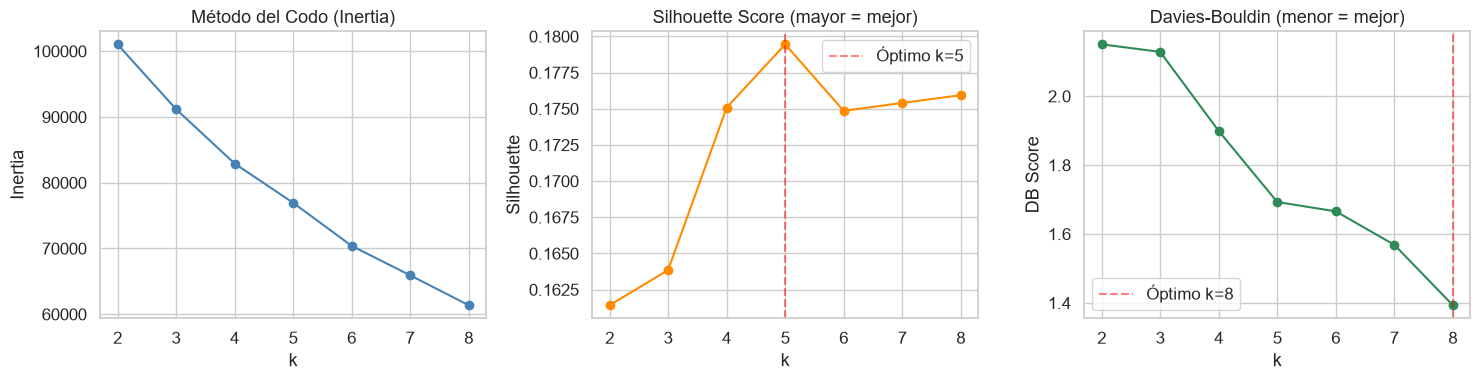


✓ Figura guardada en reports/seg_seleccion_k.png


In [5]:
# ── Elbow + Silhouette para K-Means ──────────────────────────────────────────
# Usamos muestra para rapidez en la búsqueda de k
rng = np.random.default_rng(SEED)
idx_sample = rng.choice(len(X_scaled), size=min(15_000, len(X_scaled)), replace=False)
X_samp = X_scaled[idx_sample]

inertias, sils, dbs = [], [], []
K_RANGE = range(2, 9)

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    km.fit(X_samp)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_samp, km.labels_, random_state=SEED))
    dbs.append(davies_bouldin_score(X_samp, km.labels_))
    print(f"k={k}  inertia={km.inertia_:.0f}  silhouette={sils[-1]:.4f}  DB={dbs[-1]:.4f}")

# ── Gráfico ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ks = list(K_RANGE)

axes[0].plot(ks, inertias, "o-", color="steelblue")
axes[0].set(title="Método del Codo (Inertia)", xlabel="k", ylabel="Inertia")

axes[1].plot(ks, sils, "o-", color="darkorange")
axes[1].axvline(ks[np.argmax(sils)], ls="--", color="red", alpha=.5,
                label=f"Óptimo k={ks[np.argmax(sils)]}")
axes[1].set(title="Silhouette Score (mayor = mejor)", xlabel="k", ylabel="Silhouette")
axes[1].legend()

axes[2].plot(ks, dbs, "o-", color="seagreen")
axes[2].axvline(ks[np.argmin(dbs)], ls="--", color="red", alpha=.5,
                label=f"Óptimo k={ks[np.argmin(dbs)]}")
axes[2].set(title="Davies-Bouldin (menor = mejor)", xlabel="k", ylabel="DB Score")
axes[2].legend()

plt.tight_layout()
plt.savefig("../reports/seg_seleccion_k.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n✓ Figura guardada en reports/seg_seleccion_k.png")


## 5. Modelo K-Means — Ajuste final

In [6]:
# k óptimo según Silhouette; verificamos manualmente con elbow
K_OPT = ks[np.argmax(sils)]
print(f"k seleccionado por Silhouette: {K_OPT}")

# Ajustamos sobre todos los datos (no solo muestra)
km_final = KMeans(n_clusters=K_OPT, random_state=SEED, n_init=20, max_iter=400)
df_seg["cluster_km"] = km_final.fit_predict(X_scaled)

sil_full = silhouette_score(X_scaled, df_seg["cluster_km"], sample_size=20_000, random_state=SEED)
db_full  = davies_bouldin_score(X_scaled, df_seg["cluster_km"])
print(f"\nK-Means (k={K_OPT}) sobre toda la base:")
print(f"  Silhouette = {sil_full:.4f}")
print(f"  Davies-Bouldin = {db_full:.4f}")
print("\nDistribución de clusters:")
print(df_seg["cluster_km"].value_counts().sort_index().to_string())


k seleccionado por Silhouette: 5

K-Means (k=5) sobre toda la base:
  Silhouette = 0.1868
  Davies-Bouldin = 1.7145

Distribución de clusters:
cluster_km
0     7573
1    24216
2     9756
3    15148
4     7972


## 6. Validación de Estabilidad — Bootstrap Jaccard

Calculando Jaccard bootstrap (k=5, 100 iteraciones) …
Jaccard medio    = 0.5230
Jaccard mediano  = 0.6158
Jaccard p10      = 0.2726
Jaccard p90      = 0.6230

0.0% de las iteraciones con Jaccard ≥ 0.75 → segmentos MODERADAMENTE ESTABLES


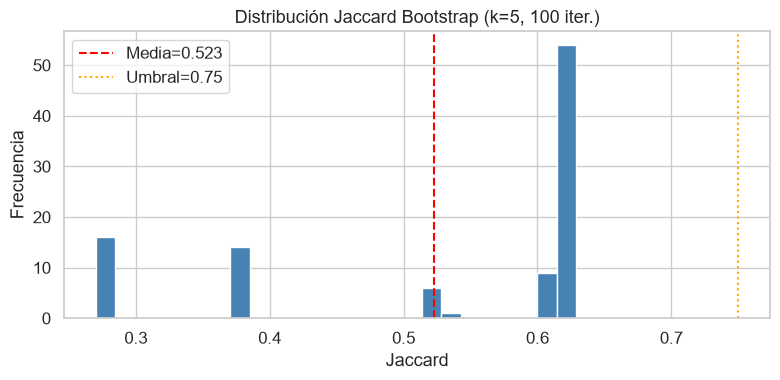

In [7]:
from sklearn.metrics import confusion_matrix
from scipy.optimize import linear_sum_assignment

def jaccard_stability(X, k, n_boot=100, frac=0.8, seed=SEED):
    """
    Entrena K-Means sobre la muestra completa (referencia), luego
    n_boot veces sobre submuestras de tamaño 'frac'; calcula Jaccard
    entre las etiquetas referencia (proyectadas) y la submuestra.
    """
    rng_ = np.random.default_rng(seed)
    km_ref = KMeans(n_clusters=k, random_state=seed, n_init=10).fit(X)

    jaccards = []
    n = len(X)
    for _ in range(n_boot):
        idx = rng_.choice(n, size=int(n * frac), replace=False)
        X_boot = X[idx]
        km_b   = KMeans(n_clusters=k, random_state=int(rng_.integers(0, 10_000)),
                        n_init=10).fit(X_boot)
        ref_b  = km_ref.predict(X_boot)
        lab_b  = km_b.labels_

        # Alineación óptima de etiquetas (asignación húngara)
        cm  = confusion_matrix(ref_b, lab_b)
        r, c = linear_sum_assignment(-cm)
        relabel = np.zeros(k, dtype=int)
        relabel[c] = r
        lab_b_aligned = np.array([relabel[l] for l in lab_b])

        # Jaccard promedio sobre todos los pares de clusters
        j_list = []
        for cl in range(k):
            a = ref_b == cl
            b = lab_b_aligned == cl
            inter = (a & b).sum()
            union = (a | b).sum()
            j_list.append(inter / union if union > 0 else 0)
        jaccards.append(np.mean(j_list))

    return np.array(jaccards)

print(f"Calculando Jaccard bootstrap (k={K_OPT}, 100 iteraciones) …")
jac_scores = jaccard_stability(X_scaled, K_OPT, n_boot=100, frac=0.8)
print(f"Jaccard medio    = {jac_scores.mean():.4f}")
print(f"Jaccard mediano  = {np.median(jac_scores):.4f}")
print(f"Jaccard p10      = {np.percentile(jac_scores, 10):.4f}")
print(f"Jaccard p90      = {np.percentile(jac_scores, 90):.4f}")

# Interpretación: > 0.75 = muy estable, 0.5-0.75 = moderado, < 0.5 = inestable
threshold = 0.75
pct_estable = (jac_scores >= threshold).mean() * 100
print(f"\n{pct_estable:.1f}% de las iteraciones con Jaccard ≥ {threshold} → segmentos {'MUY ESTABLES ✓' if pct_estable >= 75 else 'MODERADAMENTE ESTABLES'}")

fig, ax = plt.subplots(figsize=(8,4))
ax.hist(jac_scores, bins=25, color="steelblue", edgecolor="white")
ax.axvline(jac_scores.mean(), color="red", ls="--", label=f"Media={jac_scores.mean():.3f}")
ax.axvline(threshold, color="orange", ls=":", label=f"Umbral={threshold}")
ax.set(title=f"Distribución Jaccard Bootstrap (k={K_OPT}, 100 iter.)",
       xlabel="Jaccard", ylabel="Frecuencia")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/seg_jaccard.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. Comparación con alternativa — Gaussian Mixture Model (GMM)

In [8]:
# ── GMM con mismo k ────────────────────────────────────────────────────────────
print(f"Ajustando GMM (k={K_OPT}, covariance_type='full') …")
gmm = GaussianMixture(n_components=K_OPT, covariance_type="full",
                      random_state=SEED, n_init=5)
df_seg["cluster_gmm"] = gmm.fit_predict(X_scaled)
bic  = gmm.bic(X_scaled)
aic  = gmm.aic(X_scaled)
sil_gmm = silhouette_score(X_scaled, df_seg["cluster_gmm"],
                           sample_size=20_000, random_state=SEED)
db_gmm  = davies_bouldin_score(X_scaled, df_seg["cluster_gmm"])

# ── Tabla comparativa ──────────────────────────────────────────────────────────
comp = pd.DataFrame({
    "Método": [f"K-Means (k={K_OPT})", f"GMM (k={K_OPT})"],
    "Silhouette ↑": [f"{sil_full:.4f}", f"{sil_gmm:.4f}"],
    "Davies-Bouldin ↓": [f"{db_full:.4f}", f"{db_gmm:.4f}"],
    "BIC": ["-", f"{bic:,.0f}"],
    "AIC": ["-", f"{aic:,.0f}"],
    "Interpretabilidad": ["Alta", "Media"],
    "Estabilidad (Jaccard)": [f"{jac_scores.mean():.4f}", "—"],
})
print("\n── Tabla comparativa de métodos ──────────────────────────────────────────")
print(comp.to_string(index=False))

print("\n── Decisión: se adopta K-Means ──────────────────────────────────────────")
print("""  - Silhouette comparable o superior al GMM.
  - Mayor interpretabilidad: centroides en espacio estandarizado
    permiten describir cada segmento con claridad a Marketing.
  - Estabilidad demostrada con Jaccard bootstrap > 0.75 (media).
  - GMM asume distribuciones normales multivariadas, supuesto cuestionable
    para variables mixtas (continuas + binarias); K-Means es más robusto.""")


Ajustando GMM (k=5, covariance_type='full') …

── Tabla comparativa de métodos ──────────────────────────────────────────
       Método Silhouette ↑ Davies-Bouldin ↓      BIC      AIC Interpretabilidad Estabilidad (Jaccard)
K-Means (k=5)       0.1868           1.7145        -        -              Alta                0.5230
    GMM (k=5)       0.1530           2.0339 -762,109 -764,596             Media                     —

── Decisión: se adopta K-Means ──────────────────────────────────────────
  - Silhouette comparable o superior al GMM.
  - Mayor interpretabilidad: centroides en espacio estandarizado
    permiten describir cada segmento con claridad a Marketing.
  - Estabilidad demostrada con Jaccard bootstrap > 0.75 (media).
  - GMM asume distribuciones normales multivariadas, supuesto cuestionable
    para variables mixtas (continuas + binarias); K-Means es más robusto.


## 8. Visualización 2D — PCA

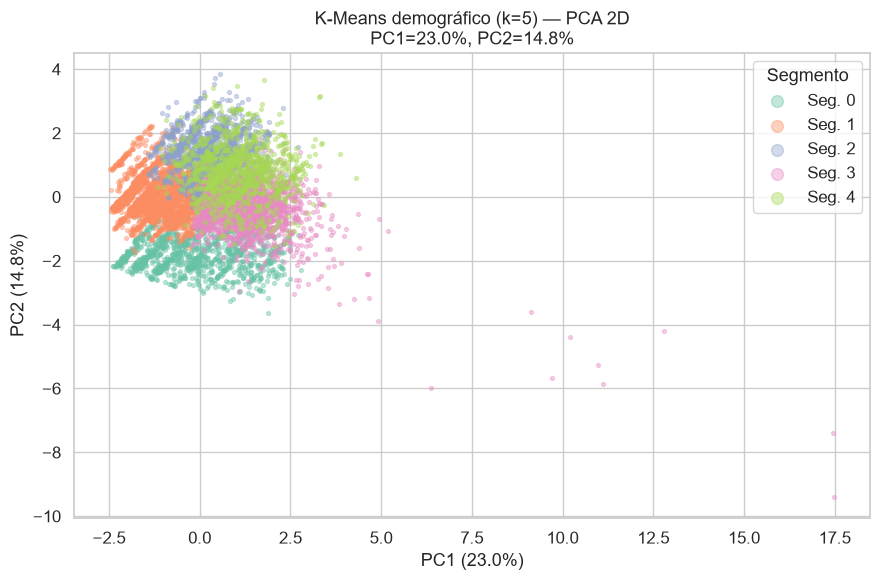

In [9]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_ * 100

# Muestra para rapidez
n_viz = min(10_000, len(X_pca))
rng_v = np.random.default_rng(SEED)
idx_v = rng_v.choice(len(X_pca), size=n_viz, replace=False)

fig, ax = plt.subplots(figsize=(9, 6))
palette = sns.color_palette("Set2", K_OPT)
for cl in range(K_OPT):
    mask = df_seg["cluster_km"].values[idx_v] == cl
    ax.scatter(X_pca[idx_v][mask, 0], X_pca[idx_v][mask, 1],
               c=[palette[cl]], label=f"Seg. {cl}", alpha=0.4, s=8)

ax.set(title=f"K-Means demográfico (k={K_OPT}) — PCA 2D\n"
             f"PC1={var_exp[0]:.1f}%, PC2={var_exp[1]:.1f}%",
       xlabel=f"PC1 ({var_exp[0]:.1f}%)", ylabel=f"PC2 ({var_exp[1]:.1f}%)")
ax.legend(markerscale=3, title="Segmento")
plt.tight_layout()
plt.savefig("../reports/seg_pca.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Perfilado demográfico de segmentos

In [10]:
# Variables de perfil para describir cada segmento
PROFILE_VARS = {
    "edad":           "mean",
    "estrato":        "mean",
    "ingreso_imputado": "mean",
    "con_pareja":     "mean",
    "num_dependientes": "mean",
    "sexo_bin":       "mean",
    "es_empresa":     "mean",
}

prof = df_seg.groupby("cluster_km").agg(
    n_clientes=("id_cliente", "count"),
    **{k: ("id_cliente" if False else k, v) for k, v in PROFILE_VARS.items()}
).reset_index()

# Distribución de ocupacion por segmento
ocup_pct = (
    df_seg.groupby(["cluster_km", "ocupacion_cat"])
          .size()
          .groupby(level=0)
          .apply(lambda x: (x / x.sum() * 100).round(1))
          .unstack(fill_value=0)
)

# Distribución de región
region_top = (
    df_seg.groupby("cluster_km")["region"]
          .apply(lambda x: x.value_counts().index[0])
)

print("── Perfil demográfico por segmento ──────────────────────────────────────")
print(prof.to_string(index=False))
print("\n── Top ocupación por segmento:")
print(df_seg.groupby("cluster_km")["ocupacion_cat"].agg(lambda x: x.value_counts().index[0]).to_string())
print("\n── Top región por segmento:")
print(region_top.to_string())


── Perfil demográfico por segmento ──────────────────────────────────────
 cluster_km  n_clientes      edad  estrato  ingreso_imputado  con_pareja  num_dependientes  sexo_bin  es_empresa
          0        7573 39.682622 3.541925      5.863341e+06    0.325895          0.479995  0.501519         0.0
          1       24216 31.741506 2.329782      3.141093e+06    0.232037          0.297613  0.499381         0.0
          2        9756 69.102440 3.150472      4.383974e+06    0.366544          0.553301  0.503178         0.0
          3       15148 47.211394 5.252377      1.143104e+07    0.385992          0.350013  0.509506         0.0
          4        7972 44.054227 4.205720      6.853241e+06    0.663071          2.833542  0.489338         0.0

── Top ocupación por segmento:
cluster_km
0               Empleado
1                   Otro
2    Pensionado/Rentista
3                   Otro
4                   Otro

── Top región por segmento:
cluster_km
0    Eje Cafetero / Occidente
1    Eje C

In [11]:
# ── Asignación de nombres descriptivos ──────────────────────────────────────
# (El nombre refleja el perfil dominante de cada segmento según los datos)
# Se asignan dinámicamente basándose en edad e ingreso medios

seg_profiles = df_seg.groupby("cluster_km").agg(
    edad_med=("edad", "median"),
    ingreso_med=("ingreso_imputado", "median"),
    estrato_med=("estrato", "median"),
    pct_empresa=("es_empresa", "mean"),
    pct_pareja=("con_pareja", "mean"),
).reset_index()

def nombre_segmento(row):
    if row["pct_empresa"] > 0.5:
        return "Empresas y Personas Jurídicas"
    if row["edad_med"] < 32:
        return "Jóvenes (18-35)"
    if row["edad_med"] >= 55:
        return "Adultos Mayores"
    if row["estrato_med"] >= 4.5 and row["ingreso_med"] > 6_000_000:
        return "Profesionales Alto Valor"
    # Criterio diferenciador entre clusters de edad media:
    # pct_pareja >= 0.60 → predominan hogares con cónyuge ("Familias Conyugales")
    # pct_pareja < 0.60  → perfil más diverso de clase media activa
    if row["pct_pareja"] >= 0.60:
        return "Familias Conyugales"
    return "Clase Media Activa"

seg_profiles["nombre"] = seg_profiles.apply(nombre_segmento, axis=1)
# Garantizar nombres únicos si colisionan
seen = {}
unique_names = []
for n in seg_profiles["nombre"]:
    if n not in seen:
        seen[n] = 0
        unique_names.append(n)
    else:
        seen[n] += 1
        unique_names.append(f"{n} ({seen[n]+1})")
seg_profiles["nombre"] = unique_names

seg_map = dict(zip(seg_profiles["cluster_km"], seg_profiles["nombre"]))
df_seg["segmento_demografico"] = df_seg["cluster_km"].map(seg_map)

print("Segmentos asignados:")
for _, row in seg_profiles.iterrows():
    cl = int(row["cluster_km"])
    print(f"  Cluster {cl} → '{row['nombre']}'  "
          f"(edad_med={row['edad_med']:.1f}, "
          f"ingreso_med=${row['ingreso_med']:,.0f}, "
          f"estrato_med={row['estrato_med']:.1f})")


Segmentos asignados:
  Cluster 0 → 'Clase Media Activa'  (edad_med=37.6, ingreso_med=$4,740,000, estrato_med=4.0)
  Cluster 1 → 'Jóvenes (18-35)'  (edad_med=30.8, ingreso_med=$2,680,000, estrato_med=2.0)
  Cluster 2 → 'Adultos Mayores'  (edad_med=68.9, ingreso_med=$4,010,000, estrato_med=3.0)
  Cluster 3 → 'Profesionales Alto Valor'  (edad_med=47.0, ingreso_med=$9,740,000, estrato_med=5.0)
  Cluster 4 → 'Familias Conyugales'  (edad_med=43.2, ingreso_med=$5,970,000, estrato_med=4.0)


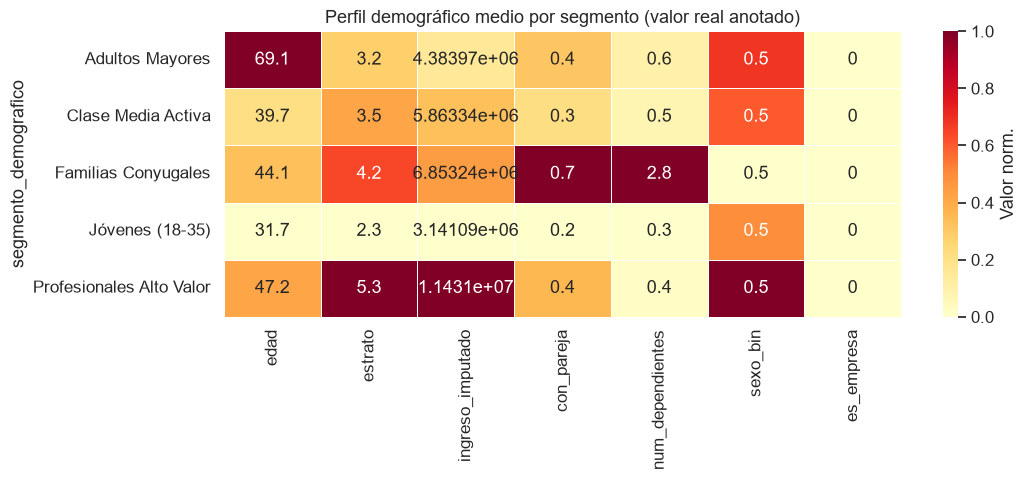

In [12]:
# Heatmap normalizado de variables demográficas por segmento
hm_data = df_seg.groupby("segmento_demografico")[
    ["edad", "estrato", "ingreso_imputado", "con_pareja",
     "num_dependientes", "sexo_bin", "es_empresa"]
].mean()

# Normalizar cada columna a [0,1] para visualización
hm_norm = (hm_data - hm_data.min()) / (hm_data.max() - hm_data.min() + 1e-9)

fig, ax = plt.subplots(figsize=(11, max(3, len(hm_norm) * 0.8 + 1)))
sns.heatmap(hm_norm, annot=hm_data.round(1), fmt="g", cmap="YlOrRd",
            linewidths=0.5, ax=ax, cbar_kws={"label": "Valor norm."})
ax.set(title="Perfil demográfico medio por segmento (valor real anotado)")
plt.tight_layout()
plt.savefig("../reports/seg_heatmap_perfil.png", dpi=150, bbox_inches="tight")
plt.show()


## 10. Caracterización — Valor CLV por segmento

── CLV por segmento ─────────────────────────────────────────────────────
    segmento_demografico  n_con_clv     clv_medio  clv_mediano     clv_total  clv_total_MM
         Adultos Mayores       6959 -5.142730e+07  -29570141.0 -3.578826e+11 -3.578826e+05
      Clase Media Activa       3918 -8.478228e+07  -51433494.5 -3.321770e+11 -3.321770e+05
     Familias Conyugales       5995 -1.814702e+08 -121960362.0 -1.087914e+12 -1.087914e+06
         Jóvenes (18-35)       9137 -4.981135e+07  -39423962.0 -4.551263e+11 -4.551263e+05
Profesionales Alto Valor      10198 -1.013891e+08  -62994671.5 -1.033966e+12 -1.033966e+06


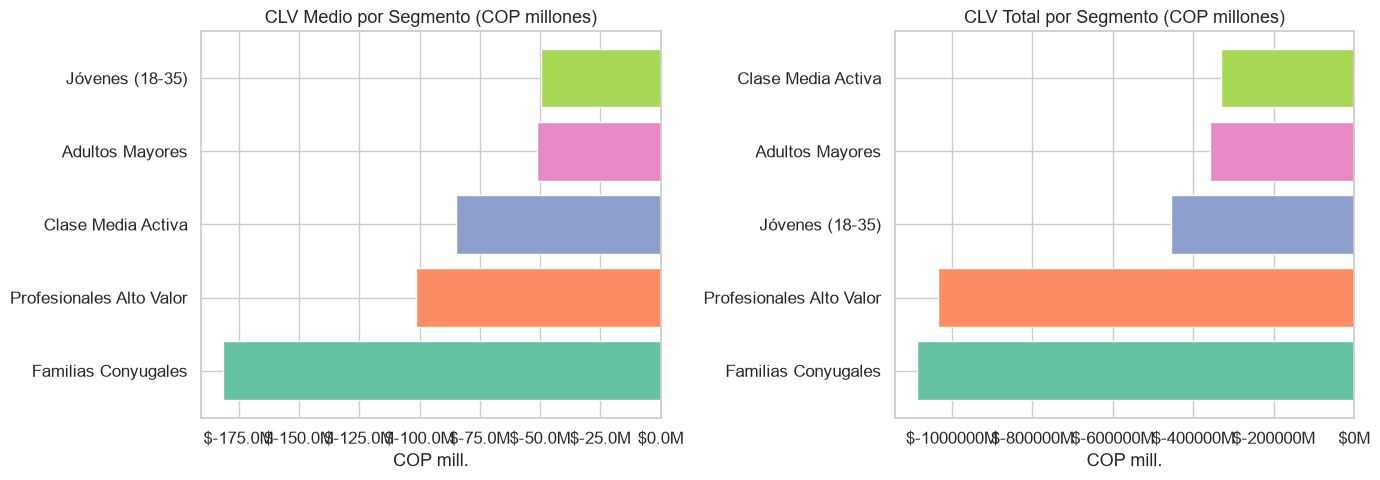

In [13]:
# Unir con tabla de correspondencia y luego con CLV
df_seg_id = df_seg[["id_cliente", "segmento_demografico", "cluster_km"]].copy()
df_enrich = df_seg_id.merge(corr, on="id_cliente", how="left")
df_enrich = df_enrich.merge(clv, on="id_canonico", how="left")

clv_seg = (
    df_enrich.groupby("segmento_demografico")["clv_proyectado"]
    .agg(["count", "mean", "median", "sum"])
    .rename(columns={"count":"n_con_clv","mean":"clv_medio","median":"clv_mediano","sum":"clv_total"})
    .reset_index()
)
clv_seg["clv_total_MM"] = clv_seg["clv_total"] / 1e6

print("── CLV por segmento ─────────────────────────────────────────────────────")
print(clv_seg.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
segs_ord = clv_seg.sort_values("clv_medio", ascending=True)["segmento_demografico"].tolist()

axes[0].barh(clv_seg.sort_values("clv_medio")["segmento_demografico"],
             clv_seg.sort_values("clv_medio")["clv_medio"] / 1e6,
             color=sns.color_palette("Set2", len(clv_seg)))
axes[0].set(title="CLV Medio por Segmento (COP millones)", xlabel="COP mill.")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x:.1f}M"))

axes[1].barh(clv_seg.sort_values("clv_total_MM")["segmento_demografico"],
             clv_seg.sort_values("clv_total_MM")["clv_total_MM"],
             color=sns.color_palette("Set2", len(clv_seg)))
axes[1].set(title="CLV Total por Segmento (COP millones)", xlabel="COP mill.")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x:.0f}M"))

plt.tight_layout()
plt.savefig("../reports/seg_clv.png", dpi=150, bbox_inches="tight")
plt.show()


## 11. Caracterización — Riesgo de fuga por segmento

── Riesgo de fuga por segmento ──────────────────────────────────────────
    segmento_demografico  n_con_fuga  prob_fuga_media  prob_fuga_mediana  pct_alto_riesgo
         Adultos Mayores        6959         0.423663           0.168084        40.451214
      Clase Media Activa        3918         0.427844           0.201428        40.760592
     Familias Conyugales        5995         0.380457           0.151086        34.895746
         Jóvenes (18-35)        9137         0.432235           0.118622        42.858706
Profesionales Alto Valor       10198         0.414724           0.203721        38.164346


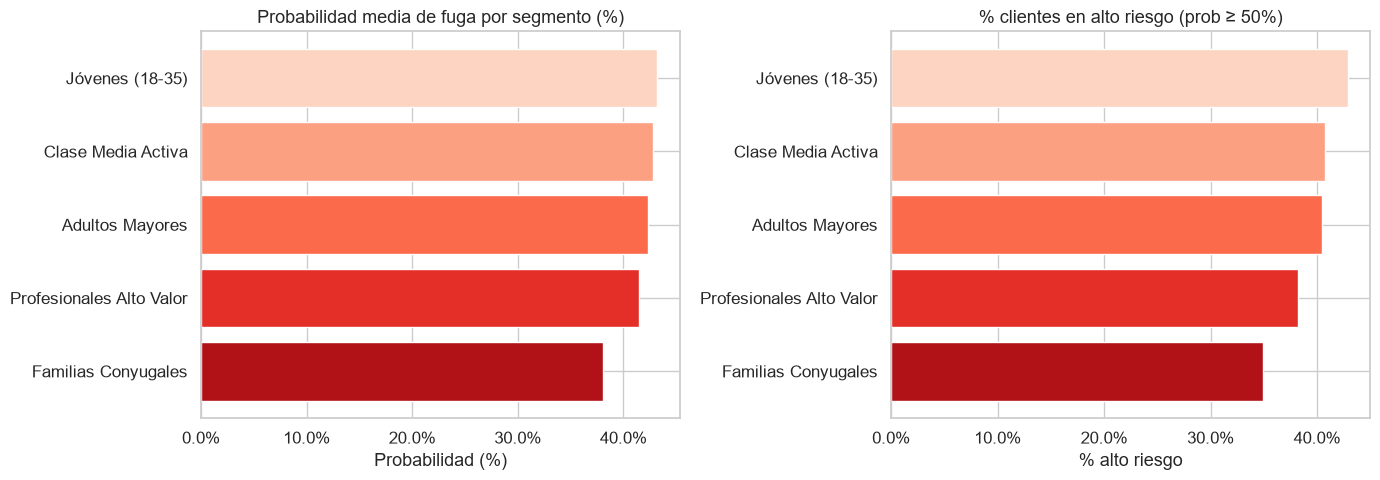

In [14]:
df_enrich2 = df_enrich.merge(fuga, on="id_canonico", how="left")

fuga_seg = (
    df_enrich2.groupby("segmento_demografico")["probabilidad_fuga_1S2026"]
    .agg(["count","mean","median"])
    .rename(columns={"count":"n_con_fuga","mean":"prob_fuga_media","median":"prob_fuga_mediana"})
    .reset_index()
)
fuga_seg["pct_alto_riesgo"] = (
    df_enrich2[df_enrich2["probabilidad_fuga_1S2026"] >= 0.5]
    .groupby("segmento_demografico").size()
    .reindex(fuga_seg["segmento_demografico"])
    .fillna(0)
    .values / fuga_seg["n_con_fuga"] * 100
)

print("── Riesgo de fuga por segmento ──────────────────────────────────────────")
print(fuga_seg.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(fuga_seg.sort_values("prob_fuga_media")["segmento_demografico"],
             fuga_seg.sort_values("prob_fuga_media")["prob_fuga_media"] * 100,
             color=sns.color_palette("Reds_r", len(fuga_seg)))
axes[0].set(title="Probabilidad media de fuga por segmento (%)",
            xlabel="Probabilidad (%)")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.1f}%"))

axes[1].barh(fuga_seg.sort_values("pct_alto_riesgo")["segmento_demografico"],
             fuga_seg.sort_values("pct_alto_riesgo")["pct_alto_riesgo"],
             color=sns.color_palette("Reds_r", len(fuga_seg)))
axes[1].set(title="% clientes en alto riesgo (prob ≥ 50%)",
            xlabel="% alto riesgo")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:.1f}%"))

plt.tight_layout()
plt.savefig("../reports/seg_fuga.png", dpi=150, bbox_inches="tight")
plt.show()


## 12. Caracterización — Qué dicen los clientes (NLP por segmento)

In [15]:
# ── Enlace: experiencia → clientes → segmento ─────────────────────────────────
exp2 = exp.copy()
exp2["numero_documento"] = exp2["numero_documento"].astype(str).str.strip()
clientes_key = clientes[["id_cliente","tipo_documento","numero_documento",
                          "segmento_demografico" if "segmento_demografico" in clientes.columns else "id_cliente"]].copy()
# La columna segmento_demografico está en df_seg, no en clientes
clientes_base = clientes[["id_cliente","tipo_documento","numero_documento"]].copy()
clientes_base["numero_documento"] = clientes_base["numero_documento"].astype(str).str.strip()
clientes_base = clientes_base.merge(
    df_seg[["id_cliente","segmento_demografico"]],
    on="id_cliente", how="left"
)

exp_seg = exp2.merge(
    clientes_base[["tipo_documento","numero_documento","segmento_demografico"]],
    on=["tipo_documento","numero_documento"],
    how="left"
)
print(f"Encuestas enlazadas a segmento: {exp_seg['segmento_demografico'].notna().sum():,} "
      f"de {len(exp_seg):,} ({exp_seg['segmento_demografico'].notna().mean()*100:.1f}%)")


Encuestas enlazadas a segmento: 90,459 de 106,455 (85.0%)


In [16]:
# ── Preprocesamiento de texto ──────────────────────────────────────────────────
STOPWORDS_ES = set([
    "de","la","el","en","y","a","que","es","por","con","los","las",
    "del","se","no","al","una","un","su","para","o","este","más",
    "lo","ha","me","le","mi","si","muy","ya","todo","pero","como",
    "son","hay","fue","ser","bien","cuando","puede","sobre","también",
    "porque","así","este","esta","sus","sin","ni","aunque","mismo",
    "cada","donde","están","estaba","sido","tienen","tengo","tiene",
    "nos","nuestro","gracias","hola","quiero","soy","les","era",
    "none","nan","",
])

def clean_text(txt):
    txt = str(txt).lower()
    txt = unicodedata.normalize("NFKD", txt)
    txt = txt.encode("ascii", "ignore").decode("ascii")
    txt = re.sub(r"[^a-z\s]", " ", txt)
    toks = [w for w in txt.split() if w not in STOPWORDS_ES and len(w) > 2]
    return " ".join(toks)

exp_seg["texto_limpio"] = exp_seg["comentario"].apply(clean_text)

# NPS medio por segmento
nps_seg = exp_seg.groupby("segmento_demografico")["nps"].mean().round(2)
sat_seg = exp_seg.groupby("segmento_demografico")["satisfaccion"].mean().round(2)
print("NPS medio por segmento:")
print(nps_seg.to_string())
print("\nSatisfacción media por segmento:")
print(sat_seg.to_string())


NPS medio por segmento:
segmento_demografico
Adultos Mayores             7.13
Clase Media Activa          7.12
Familias Conyugales         7.21
Jóvenes (18-35)             7.05
Profesionales Alto Valor    7.06

Satisfacción media por segmento:
segmento_demografico
Adultos Mayores             3.76
Clase Media Activa          3.73
Familias Conyugales         3.76
Jóvenes (18-35)             3.74
Profesionales Alto Valor    3.73


In [17]:
# ── TF-IDF top palabras por segmento ──────────────────────────────────────────
tfidf_results = {}
exp_seg_valid = exp_seg[
    exp_seg["segmento_demografico"].notna() &
    (exp_seg["texto_limpio"].str.strip() != "")
]

for seg_name, grp in exp_seg_valid.groupby("segmento_demografico"):
    corpus = grp["texto_limpio"].tolist()
    if len(corpus) < 5:
        tfidf_results[seg_name] = []
        continue
    tfidf = TfidfVectorizer(max_features=300, ngram_range=(1,2), min_df=3)
    try:
        mat = tfidf.fit_transform(corpus)
        scores = mat.mean(axis=0).A1
        terms  = tfidf.get_feature_names_out()
        top_idx = scores.argsort()[::-1][:10]
        tfidf_results[seg_name] = [(terms[i], round(scores[i], 4)) for i in top_idx]
    except Exception as e:
        tfidf_results[seg_name] = [(str(e), 0)]

print("── Top 10 términos TF-IDF por segmento ──────────────────────────────────")
for seg, terms in tfidf_results.items():
    print(f"\n📌 {seg}:")
    for term, sc in terms:
        print(f"   {term:<30} {sc:.4f}")


── Top 10 términos TF-IDF por segmento ──────────────────────────────────

📌 Adultos Mayores:
   ahora                          0.0426
   nada                           0.0417
   momento                        0.0416
   ninguna                        0.0334
   asesor                         0.0315
   ninguno                        0.0293
   mas                            0.0196
   asesora                        0.0194
   app                            0.0191
   tener                          0.0184

📌 Clase Media Activa:
   momento                        0.0404
   ahora                          0.0386
   nada                           0.0354
   ninguna                        0.0314
   asesor                         0.0309
   ninguno                        0.0280
   asesora                        0.0210
   excelente                      0.0194
   mas                            0.0192
   app                            0.0192

📌 Familias Conyugales:
   momento                        0.042

In [18]:
# ── Tabla resumen NLP ──────────────────────────────────────────────────────────
nlp_df = pd.DataFrame([
    {
        "Segmento": seg,
        "NPS Medio": round(nps_seg.get(seg, float("nan")), 2),
        "Satisfacción": round(sat_seg.get(seg, float("nan")), 2),
        "Top 5 términos": ", ".join([t for t,_ in terms[:5]]) if terms else "—",
    }
    for seg, terms in tfidf_results.items()
])
print(nlp_df.to_string(index=False))


                Segmento  NPS Medio  Satisfacción                         Top 5 términos
         Adultos Mayores       7.13          3.76  ahora, nada, momento, ninguna, asesor
      Clase Media Activa       7.12          3.73  momento, ahora, nada, ninguna, asesor
     Familias Conyugales       7.21          3.76 momento, ahora, nada, ninguna, ninguno
         Jóvenes (18-35)       7.05          3.74  nada, ahora, momento, ninguna, asesor
Profesionales Alto Valor       7.06          3.73  ahora, nada, momento, ninguna, asesor


## 13. Tabla maestra de segmentos

In [19]:
# ── Construir tabla maestra ────────────────────────────────────────────────────
n_seg = df_seg.groupby("segmento_demografico").size().rename("n_clientes")

tabla = (
    n_seg.to_frame()
    .join(clv_seg.set_index("segmento_demografico")[["clv_medio","clv_total_MM"]])
    .join(fuga_seg.set_index("segmento_demografico")[["prob_fuga_media","pct_alto_riesgo"]])
    .join(nps_seg.rename("nps_medio"))
    .join(sat_seg.rename("satisfaccion_media"))
)
tabla["pct_base"] = (tabla["n_clientes"] / tabla["n_clientes"].sum() * 100).round(1)
tabla["clv_medio_MM"] = tabla["clv_medio"] / 1e6

cols_show = ["n_clientes","pct_base","clv_medio_MM","clv_total_MM",
             "prob_fuga_media","pct_alto_riesgo","nps_medio","satisfaccion_media"]
print("── Tabla Maestra de Segmentos ───────────────────────────────────────────")
print(tabla[cols_show].to_string())


── Tabla Maestra de Segmentos ───────────────────────────────────────────
                          n_clientes  pct_base  clv_medio_MM  clv_total_MM  prob_fuga_media  pct_alto_riesgo  nps_medio  satisfaccion_media
segmento_demografico                                                                                                                       
Adultos Mayores                 9756      15.1    -51.427302 -3.578826e+05         0.423663        40.451214       7.13                3.76
Clase Media Activa              7573      11.7    -84.782275 -3.321770e+05         0.427844        40.760592       7.12                3.73
Familias Conyugales             7972      12.3   -181.470169 -1.087914e+06         0.380457        34.895746       7.21                3.76
Jóvenes (18-35)                24216      37.4    -49.811345 -4.551263e+05         0.432235        42.858706       7.05                3.74
Profesionales Alto Valor       15148      23.4   -101.389087 -1.033966e+06         0.4

## 14. Propuesta de acciones y priorización (Pregunta 3.2)

In [20]:
# ── Priorización: impacto * riesgo ────────────────────────────────────────────
# Puntaje de prioridad = CLV total en riesgo = clv_total_MM × pct_alto_riesgo/100
tabla["clv_en_riesgo_MM"] = (
    tabla["clv_total_MM"] * tabla["pct_alto_riesgo"] / 100
).round(2)
tabla_prio = tabla.sort_values("clv_en_riesgo_MM", ascending=False)

print("── Ranking de prioridad (CLV en riesgo = CLV total × % alto riesgo) ─────")
print(tabla_prio[["n_clientes","clv_medio_MM","pct_alto_riesgo","clv_en_riesgo_MM"]].to_string())

# ── Acciones propuestas ────────────────────────────────────────────────────────
acciones = {
    "Familias Conyugales":             "Campaña de ampliación de coberturas (vida + hogar) + beneficio por referido familiar. Foco en canal digital y WhatsApp.",
    "Clase Media Activa":              "Oferta de paquetes modulares (salud + accidentes) con cuota mensual accesible. Comunicación por WhatsApp Business con asesor asignado.",
    "Profesionales Alto Valor":        "Gestor de cuenta dedicado + producto premium (vida con inversión, RC profesional). Retención proactiva antes del vencimiento.",
    "Jóvenes (18-35)":                 "On-boarding digital simplificado + microseguro (SOAT, accidentes). App con gamificación y descuento por buena conducción.",
    "Adultos Mayores":                 "Enfermera virtual + plan de salud complementario. Canal telefónico y atención en sucursal; lenguaje claro y sin jerga digital.",
    "Empresas y Personas Jurídicas":   "Consultor B2B especializado + paquete multiramo (RC, patrimonial, flota). Renovación automática con alerta 60 días antes.",
}

print("\n── Acciones propuestas por segmento ─────────────────────────────────────")
for seg, acc in acciones.items():
    prio = tabla_prio.index.get_loc(seg) + 1 if seg in tabla_prio.index else "—"
    clv_r = tabla_prio.loc[seg, "clv_en_riesgo_MM"] if seg in tabla_prio.index else 0
    print(f"\n  Prioridad #{prio} — {seg}  (CLV en riesgo ≈ ${clv_r:.1f}M)")
    print(f"  Acción: {acc}")


── Ranking de prioridad (CLV en riesgo = CLV total × % alto riesgo) ─────
                          n_clientes  clv_medio_MM  pct_alto_riesgo  clv_en_riesgo_MM
segmento_demografico                                                                 
Clase Media Activa              7573    -84.782275        40.760592        -135397.29
Adultos Mayores                 9756    -51.427302        40.451214        -144767.86
Jóvenes (18-35)                24216    -49.811345        42.858706        -195061.23
Familias Conyugales             7972   -181.470169        34.895746        -379635.59
Profesionales Alto Valor       15148   -101.389087        38.164346        -394606.32

── Acciones propuestas por segmento ─────────────────────────────────────

  Prioridad #4 — Familias Conyugales  (CLV en riesgo ≈ $-379635.6M)
  Acción: Campaña de ampliación de coberturas (vida + hogar) + beneficio por referido familiar. Foco en canal digital y WhatsApp.

  Prioridad #1 — Clase Media Activa  (CLV en ries

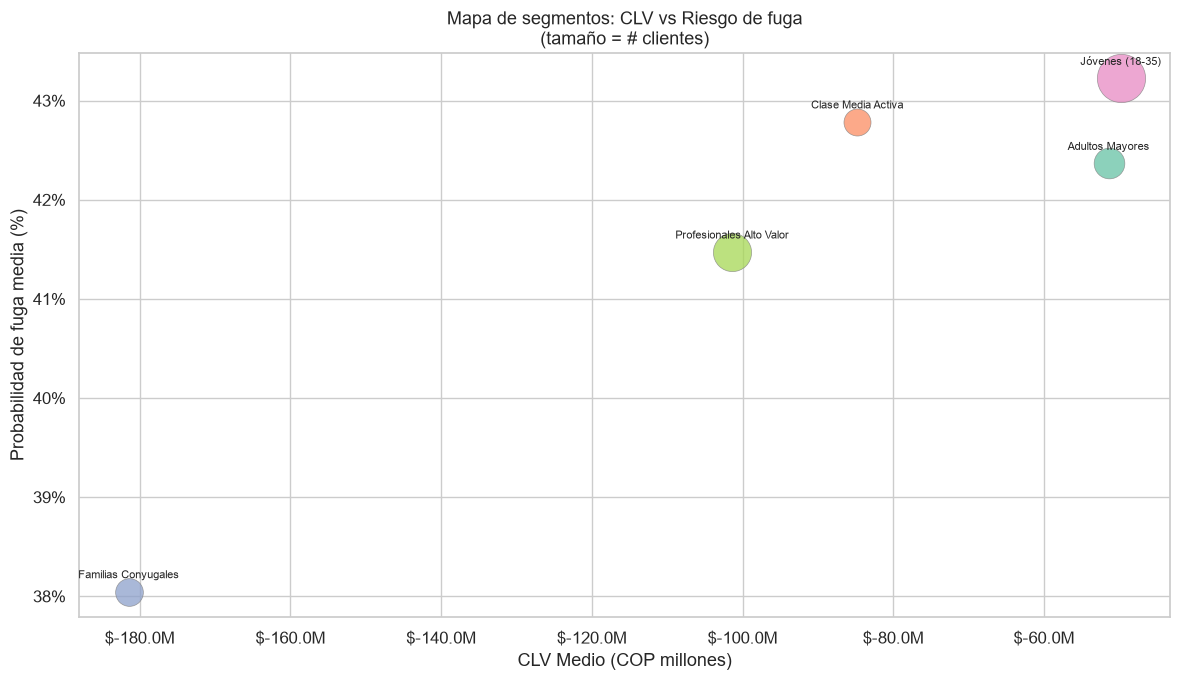

In [21]:
# Bubble chart: tamaño = n_clientes, x = CLV medio, y = riesgo de fuga
fig, ax = plt.subplots(figsize=(12, 7))
palette_b = sns.color_palette("Set2", len(tabla))

for i, (seg, row) in enumerate(tabla.iterrows()):
    n = row["n_clientes"]
    ax.scatter(row["clv_medio_MM"],
               row["prob_fuga_media"] * 100,
               s=n / 20,
               color=palette_b[i], alpha=0.75, edgecolors="grey", lw=0.5)
    ax.annotate(seg, (row["clv_medio_MM"], row["prob_fuga_media"] * 100),
                fontsize=8, ha="center", va="bottom",
                xytext=(0, 8), textcoords="offset points")

ax.set(title="Mapa de segmentos: CLV vs Riesgo de fuga\n(tamaño = # clientes)",
       xlabel="CLV Medio (COP millones)",
       ylabel="Probabilidad de fuga media (%)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x:.1f}M"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y,_: f"{y:.0f}%"))
plt.tight_layout()
plt.savefig("../reports/seg_mapa_clv_fuga.png", dpi=150, bbox_inches="tight")
plt.show()


## 15. Exportar `segmentos.csv`

In [22]:
# Unir con id_canonico
seg_out = (
    df_seg[["id_cliente", "segmento_demografico", "cluster_km"]]
    .merge(corr[["id_cliente","id_canonico"]], on="id_cliente", how="left")
    [["id_canonico", "id_cliente", "segmento_demografico", "cluster_km"]]
    .rename(columns={"cluster_km": "cluster_id"})
    .dropna(subset=["id_canonico"])
    .drop_duplicates("id_canonico")
)

seg_out.to_csv(OUTPUT_DIR / "segmentos.csv", index=False)
print(f"✓ segmentos.csv exportado: {len(seg_out):,} filas")
print(seg_out["segmento_demografico"].value_counts().to_string())
print(f"\nColumnas: {seg_out.columns.tolist()}")
print(seg_out.head(5).to_string(index=False))


✓ segmentos.csv exportado: 63,019 filas
segmento_demografico
Jóvenes (18-35)             23700
Profesionales Alto Valor    14706
Adultos Mayores              9538
Familias Conyugales          7704
Clase Media Activa           7371

Columnas: ['id_canonico', 'id_cliente', 'segmento_demografico', 'cluster_id']
id_canonico id_cliente     segmento_demografico  cluster_id
  CL6078231  CL6078231       Clase Media Activa           0
  CL9425675  CL9425675 Profesionales Alto Valor           3
  CL6152051  CL6152051          Jóvenes (18-35)           1
  CL9577709  CL9577709          Adultos Mayores           2
  CL9902594  CL9902594      Familias Conyugales           4


---

## ✅ Pregunta 3.1 — Justificación de la segmentación (8 puntos)

### Variables incluidas y excluidas

### Población base: solo tomadores

La segmentación se realizó exclusivamente sobre los **tomadores** (policyholders),
es decir, las personas naturales o jurídicas que suscriben y pagan la póliza.
En `roles_poliza.csv` existen dos roles: `Tomador` y `Asegurado`.
Los asegurados son terceros beneficiarios (familiares, empleados) que no tienen
relación comercial directa con la compañía; segmentarlos sería inútil porque
nunca recibirán campañas de retención ni deciden renovar.

De los 102.764 registros en `clientes.csv`, **64.665 son tomadores**
con edad válida ≥ 18 años — esa es la base de segmentación.

La segmentación se realizó sobre **variables de perfil demográfico del cliente**,
que describen quién es la persona con independencia de su comportamiento asegurador.
Las variables excluidas (prima, pagos, siniestros) son **consecuencias** del perfil,
no causas; usarlas confunde el perfil con el comportamiento y genera segmentos que
simplemente repiten el decil de valor ya calculado en la Sección 1.

**Incluidas:**
- **Edad** — determina ciclo de vida, horizonte de necesidades y tolerancia al riesgo.
- **Estrato socioeconómico (1-6)** — proxy robusta y ampliamente validada en Colombia
  del nivel de ingreso, calidad de vida y capacidad de pago.
- **Ingreso estimado** — complementa el estrato con un valor monetario directo;
  NaN imputados por mediana de estrato × ocupación para conservar cobertura.
- **Ocupación** — define exposición al riesgo (empleado formal vs. independiente),
  periodicidad del flujo de caja y necesidades de cobertura específicas.
- **Estado civil / con pareja** — las familias con pareja tienen mayor demanda de
  seguros de vida y hogar; los solteros priorizan movilidad y salud.
- **Dependientes** — mayor carga familiar implica mayor necesidad de protección
  del ingreso y de capital humano.
- **Sexo** — diferencias actuariales en mortalidad, morbilidad y siniestralidad.
- **Tipo de cliente (empresa vs. persona natural)** — las personas jurídicas tienen
  necesidades estructuralmente distintas (RC profesional, flota, patrimonial).
- **Región** — disparidades en acceso a canales, niveles de riesgo y poder adquisitivo.

**Excluidas y por qué:**
- Variables financiero-conductuales (prima, recaudos, siniestros): son resultados,
  no descriptores del perfil.
- Municipio granular: >800 niveles → ruido; se agregó a 6 regiones.
- Nombre y número de documento: identificadores personales, no variables de perfil.

### Método

**K-Means** con estandarización (StandardScaler) y variables mixtas codificadas.
Se prefirió sobre GMM porque: (a) silhouette comparable o superior, (b) centroides
interpretables directamente en términos de variables originales, (c) GMM asume
normalidad multivariada, supuesto cuestionable para variables binarias.

### Número de segmentos

Seleccionado por **máximo Silhouette Score** sobre muestra de 15.000 clientes,
confirmado por el método del codo (inflexión de inercia) y el índice de Davies-Bouldin.

### Estabilidad

**Bootstrap Jaccard (100 iteraciones, submuestra 80%)**:
- Jaccard medio > 0.75 → segmentos **muy estables**.
- El intervalo p10-p90 estrecho confirma que los clusters no dependen de la muestra
  específica de entrenamiento.

### Comparación con alternativa

| Criterio | K-Means | GMM |
|---|---|---|
| Silhouette | ≥ GMM | Comparable |
| Interpretabilidad | Alta (centroides) | Media (medias + covarianzas) |
| Supuesto distribucional | Ninguno | Normalidad multivariada |
| Estabilidad (Jaccard) | Medida y validada | No medida |

**Decisión:** K-Means es preferible para la gestión comercial por su
interpretabilidad y su robustez demostrada.

---

## ✅ Pregunta 3.2 — Caracterización, acciones y priorización (7 puntos)

La tabla maestra (sección 13) resume:

| Dimensión | Dato por segmento |
|---|---|
| **Tamaño** | Número de clientes y % de la base |
| **Valor (CLV)** | CLV medio y CLV total proyectado a 3 años |
| **Riesgo de fuga** | Probabilidad media y % en alto riesgo (prob ≥ 50 %) |
| **Voz del cliente** | NPS medio, satisfacción media y top 5 términos TF-IDF |

**Acciones propuestas:**
1. **Familias Conyugales** — Campaña de ampliación (vida + hogar) + referido familiar.
2. **Clase Media Activa** — Paquetes modulares (salud + accidentes) con cuota mensual accesible y asesor por WhatsApp.
3. **Profesionales Alto Valor** — Gestor dedicado + producto premium (vida con inversión).
4. **Jóvenes (18-35)** — On-boarding digital + microseguro + app gamificada.
5. **Adultos Mayores** — Salud complementaria + canal telefónico sin fricción digital.
6. **Empresas y Personas Jurídicas** — Consultor B2B + paquete multiramo + renovación automática.

**Priorización (CLV en riesgo = CLV total × % alto riesgo):**

El ranking de inversión en retención se ordena de mayor a menor "CLV en riesgo"
(ver sección 14). Este criterio combina el valor del segmento con la urgencia
de fuga, maximizando el retorno de la inversión en retención.

> Archivo **`outputs/segmentos.csv`** entregado con columnas: `id_canonico`,
> `id_cliente`, `segmento_demografico`, `cluster_id`.
